# Air temperature projections

Multi-model CMIP6 projections prepared by CSIRO on a common 1° Pacific grid. Every model's annual series is averaged over each EEZ and ocean region (cosine-of-latitude weights) and expressed as the change relative to its own 2015–2035 mean. For each indicator:

* **Trend map** — linear trend over 2015–2100 of the multi-model median change in each EEZ, one panel per scenario.
* **Warming-level map** — multi-model median change in each EEZ in the year `map_scenario` first reaches each global warming level.
* **Ocean-region box plots** — spread across models at each warming level for the four ocean regions, one figure per region.

```{glue:figure} tas_fig
:scale: 60%
:align: center
```

**Figure. Change in mean temperature relative to 2015–2035 in each Pacific EEZ at the global warming levels** (multi-model median, `map_scenario`).

In [1]:
# CIndRA notebook display standard
import matplotlib as mpl

mpl.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 13,
    'figure.dpi': 100,
    'savefig.dpi': 150,
})

## Setup

Regional helpers come from `functions/projections_regional.py` (EEZ and ocean-region means, maps, box plots) and `functions/projections.py` (data access, warming levels); the box plots use `ind_setup.plotting_projections` from the [indicators_setup](https://github.com/lauracagigal/indicators_setup) repository.

In [2]:
import warnings
warnings.filterwarnings("ignore")

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from myst_nb import glue

sys.path.append("../../../../../../indicators_setup")
sys.path.append("../../../../functions")
import projections as prj
import projections_regional as reg

### Configuration

Scenarios and global warming levels are the ones of the national projections ([`../../National/00_warming_levels.ipynb`](../../National/00_warming_levels.ipynb)). Maps of the change at warming levels use `map_scenario`; box plots show every scenario. Figures go to `outputs/figures/regional_pacific/PRJ_*` and tables to `outputs/tables/regional_pacific/PRJ_*`.

In [3]:
ssp_scenarios = ['ssp126', 'ssp245', 'ssp370', 'ssp585']
map_scenario = "ssp370"
scenario_info = prj.load_warming_levels(ssp_scenarios)

eez = reg.load_eez()
fig_dir = Path("../../../../outputs/figures/regional_pacific")
tables_dir = Path("../../../../outputs/tables/regional_pacific")
fig_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)

## Mean temperature

Annual mean near-surface air temperature (°C).

,Region,Scenario,Warming level,Year,Models,Median,P10,P90,Min,Max
0,North Pacific Subtropical Gyre,SSP126,+1.5°C,2032,38,0.167,-0.110,0.318,-0.181,0.435
1,North Pacific Subtropical Gyre,SSP126,+2.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
2,North Pacific Subtropical Gyre,SSP126,+2.5°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
3,North Pacific Subtropical Gyre,SSP126,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
4,North Pacific Subtropical Gyre,SSP245,+1.5°C,2030,38,0.134,-0.000,0.326,-0.132,0.432
...,...,...,...,...,...,...,...,...,...,...
59,South Pacific Subtropical Gyre,SSP370,+3.0°C,2075,38,1.327,0.746,1.706,0.417,1.954
60,South Pacific Subtropical Gyre,SSP585,+1.5°C,2027,38,0.043,-0.193,0.231,-0.492,0.322
61,South Pacific Subtropical Gyre,SSP585,+2.0°C,2041,38,0.432,0.218,0.688,-0.017,0.749
62,South Pacific Subtropical Gyre,SSP585,+2.5°C,2053,38,0.779,0.471,1.070,0.170,1.558


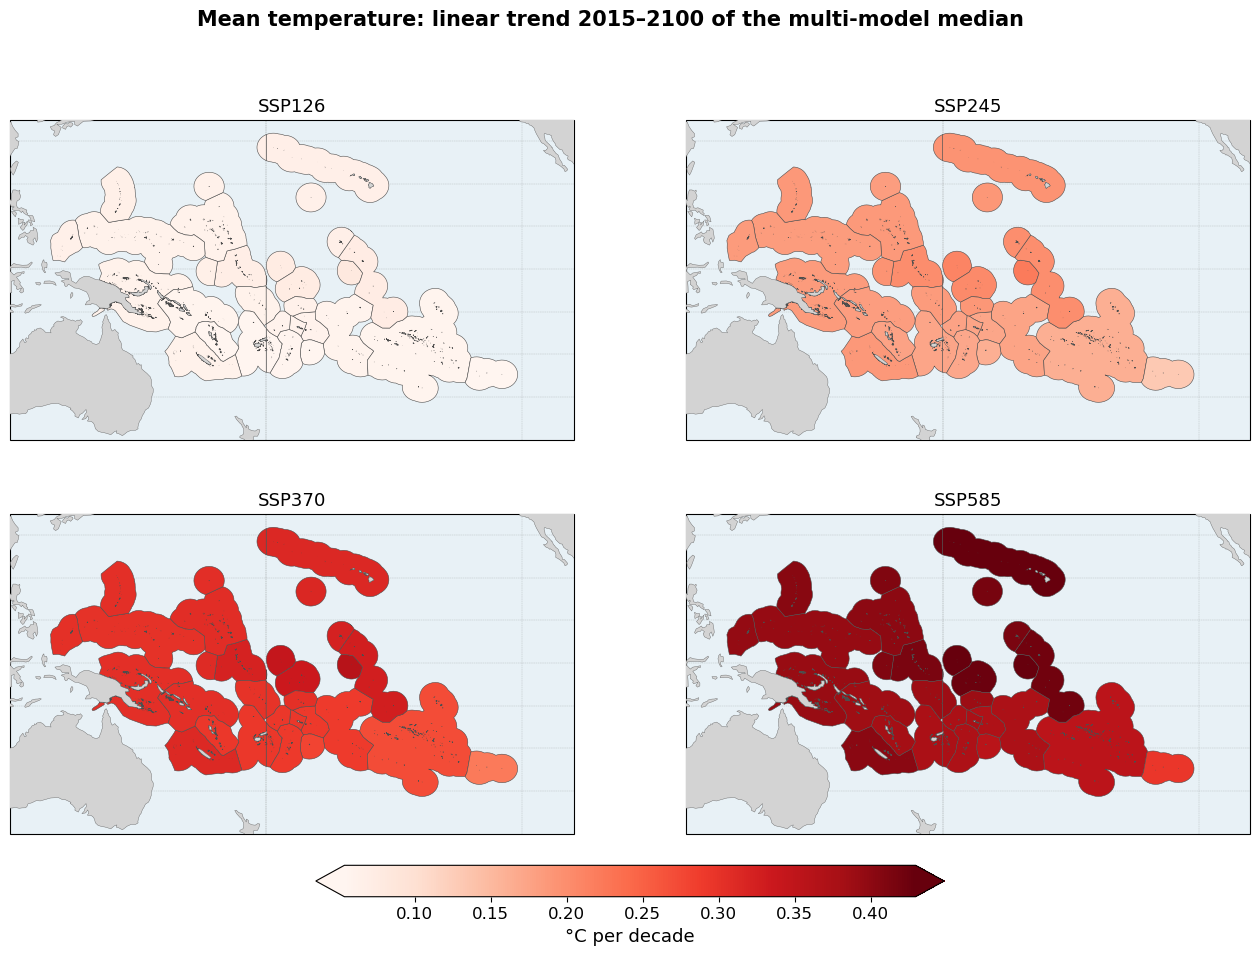

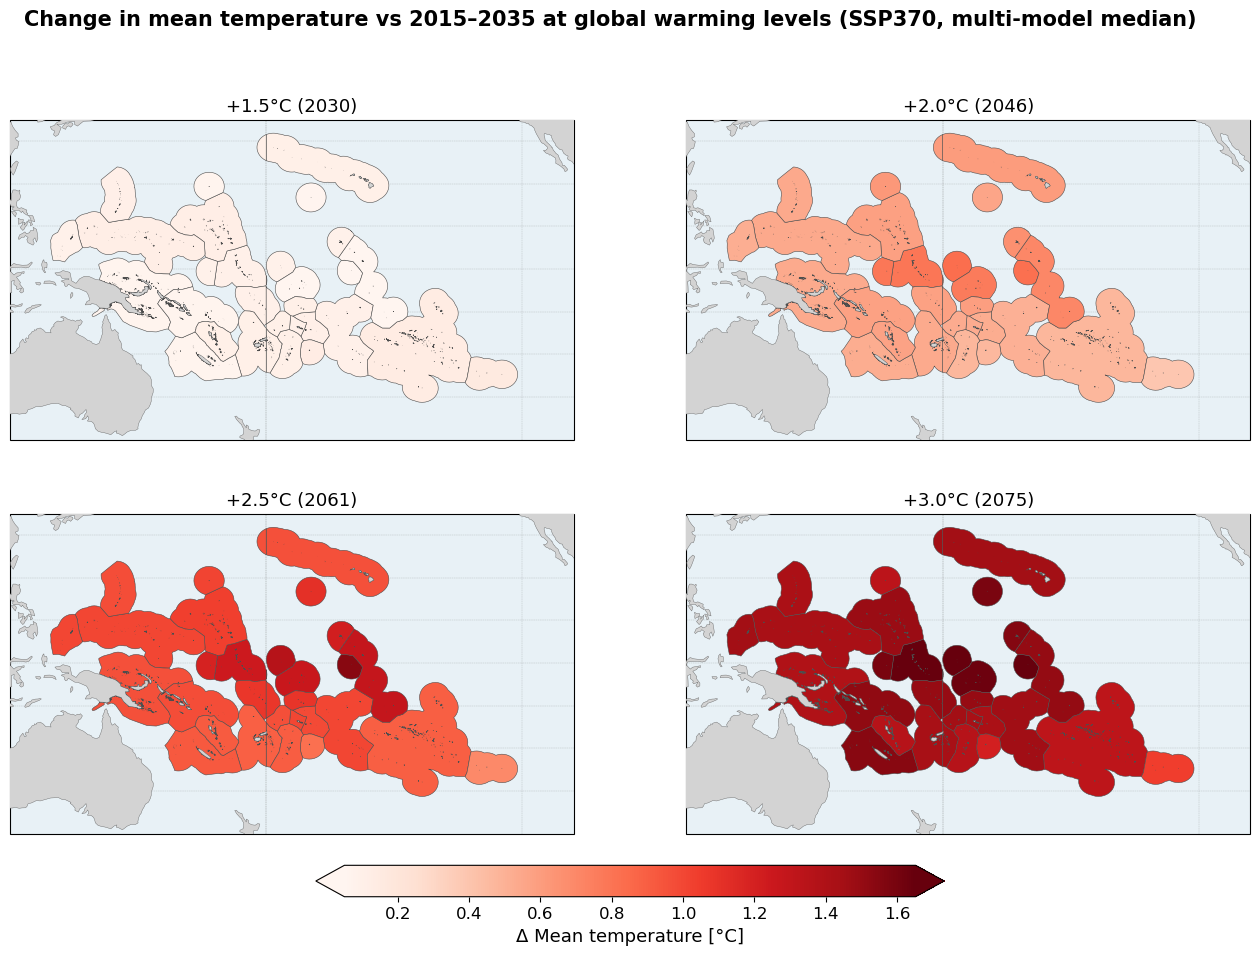

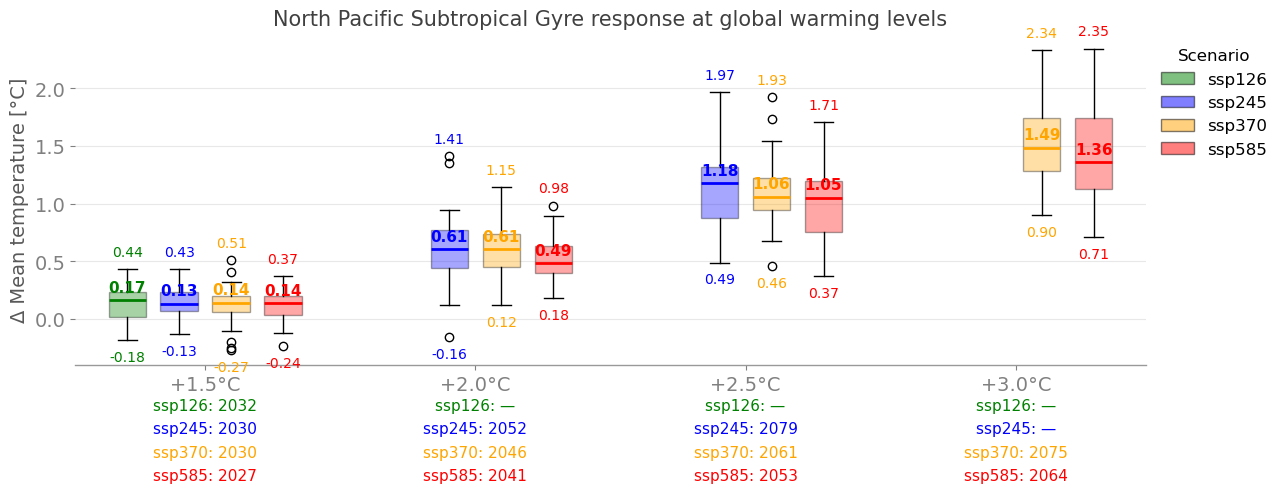

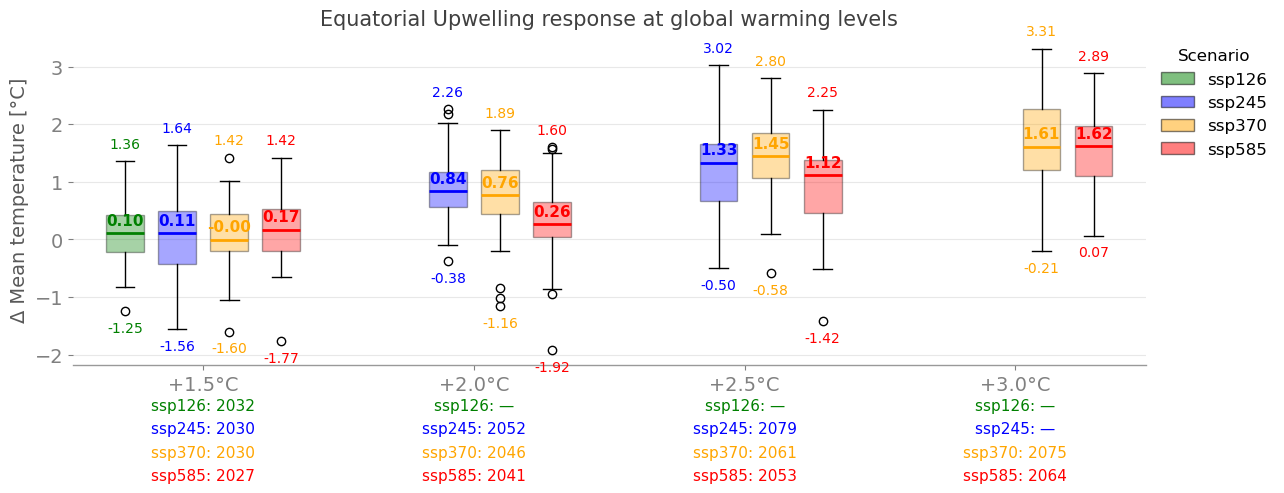

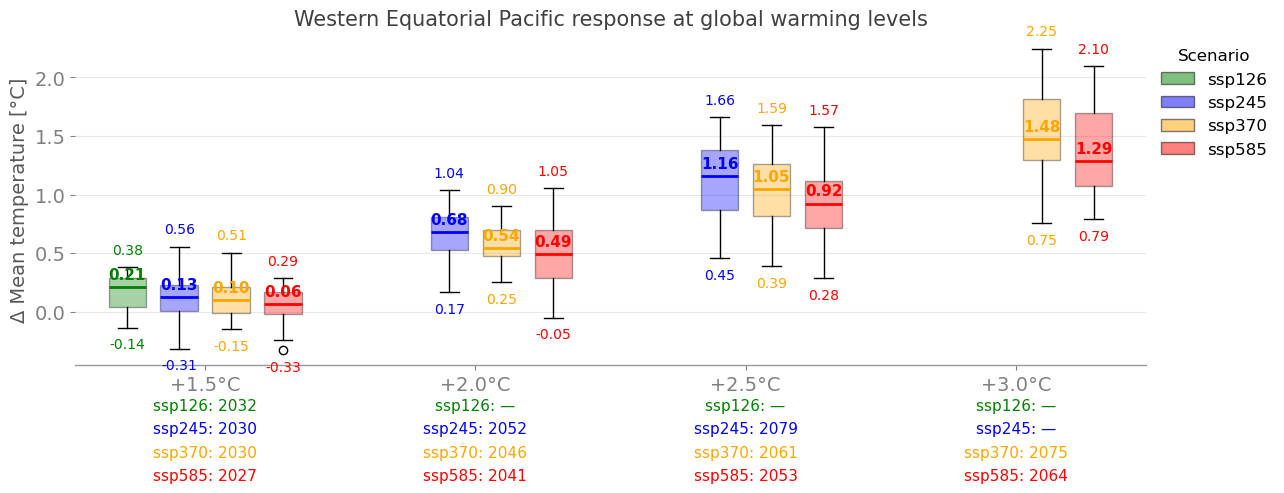

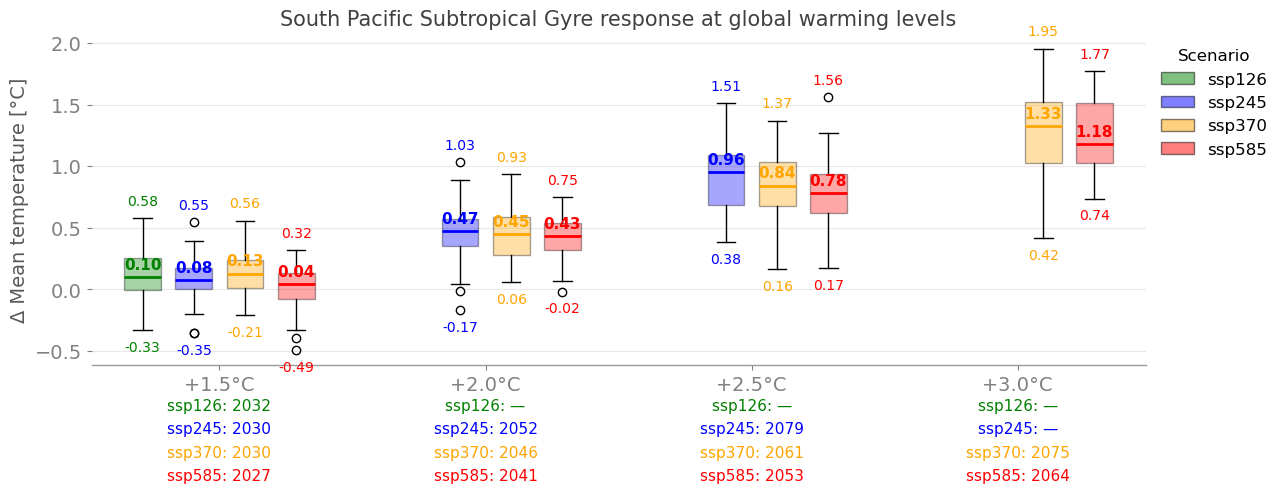

In [4]:
ds = reg.extract_regional_means("tas", eez, ssp_scenarios)
figs, tables = reg.indicator_report(ds, "tas", scenario_info, eez, ssp_scenarios, map_scenario, fig_dir, tables_dir)
glue("tas_fig", figs["levels"], display=False)
tables["regions"]

## Minimum temperature

Annual minimum near-surface air temperature (°C).

,Region,Scenario,Warming level,Year,Models,Median,P10,P90,Min,Max
0,North Pacific Subtropical Gyre,SSP126,+1.5°C,2032,27,0.165,-0.004,0.334,-0.150,0.364
1,North Pacific Subtropical Gyre,SSP126,+2.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
2,North Pacific Subtropical Gyre,SSP126,+2.5°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
3,North Pacific Subtropical Gyre,SSP126,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
4,North Pacific Subtropical Gyre,SSP245,+1.5°C,2030,27,0.147,-0.032,0.335,-0.124,0.430
...,...,...,...,...,...,...,...,...,...,...
59,South Pacific Subtropical Gyre,SSP370,+3.0°C,2075,27,1.381,0.902,1.726,0.702,1.976
60,South Pacific Subtropical Gyre,SSP585,+1.5°C,2027,27,0.065,-0.169,0.221,-0.492,0.322
61,South Pacific Subtropical Gyre,SSP585,+2.0°C,2041,27,0.446,0.176,0.622,-0.003,0.724
62,South Pacific Subtropical Gyre,SSP585,+2.5°C,2053,27,0.813,0.464,1.001,0.175,1.579


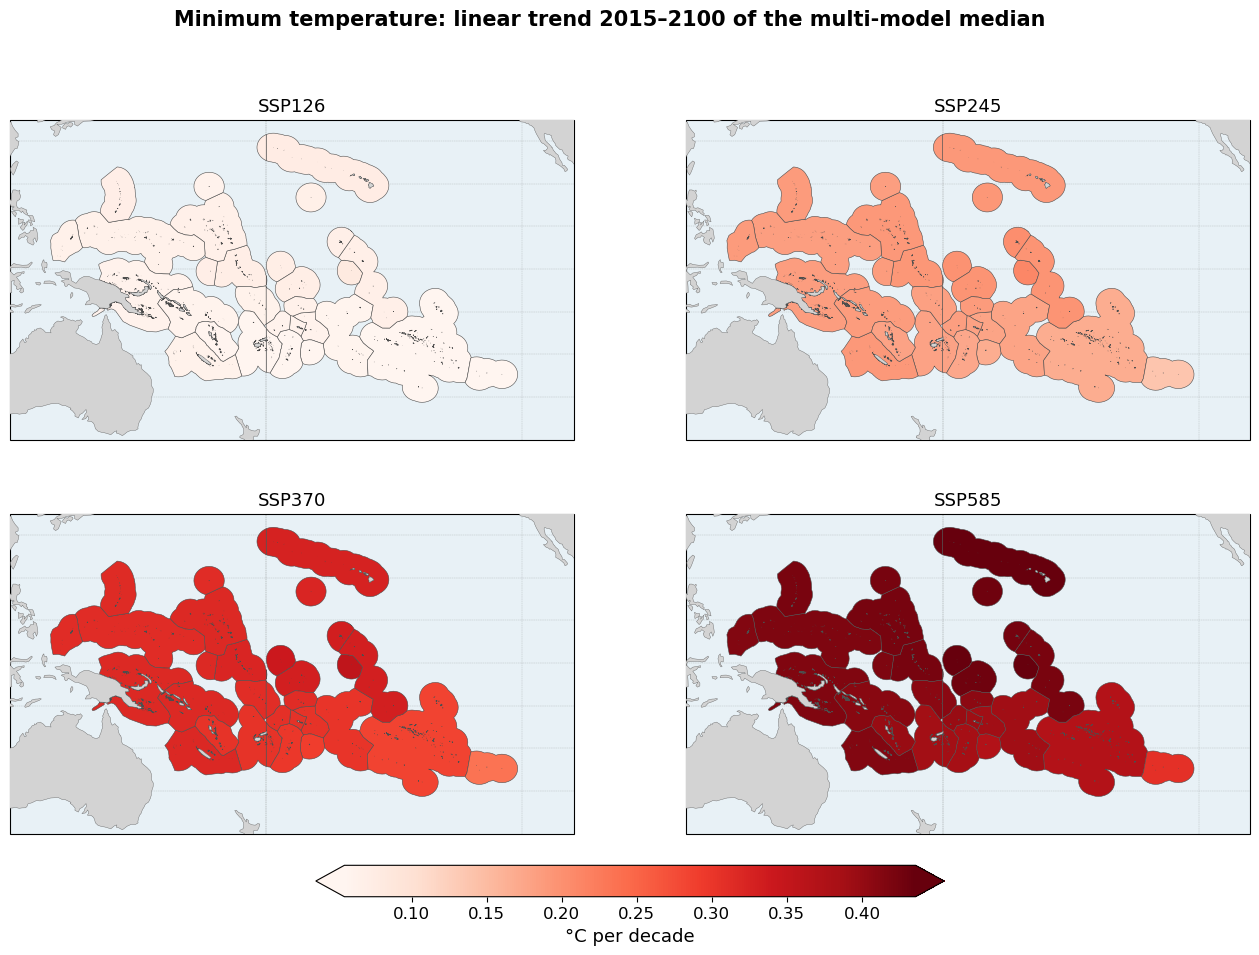

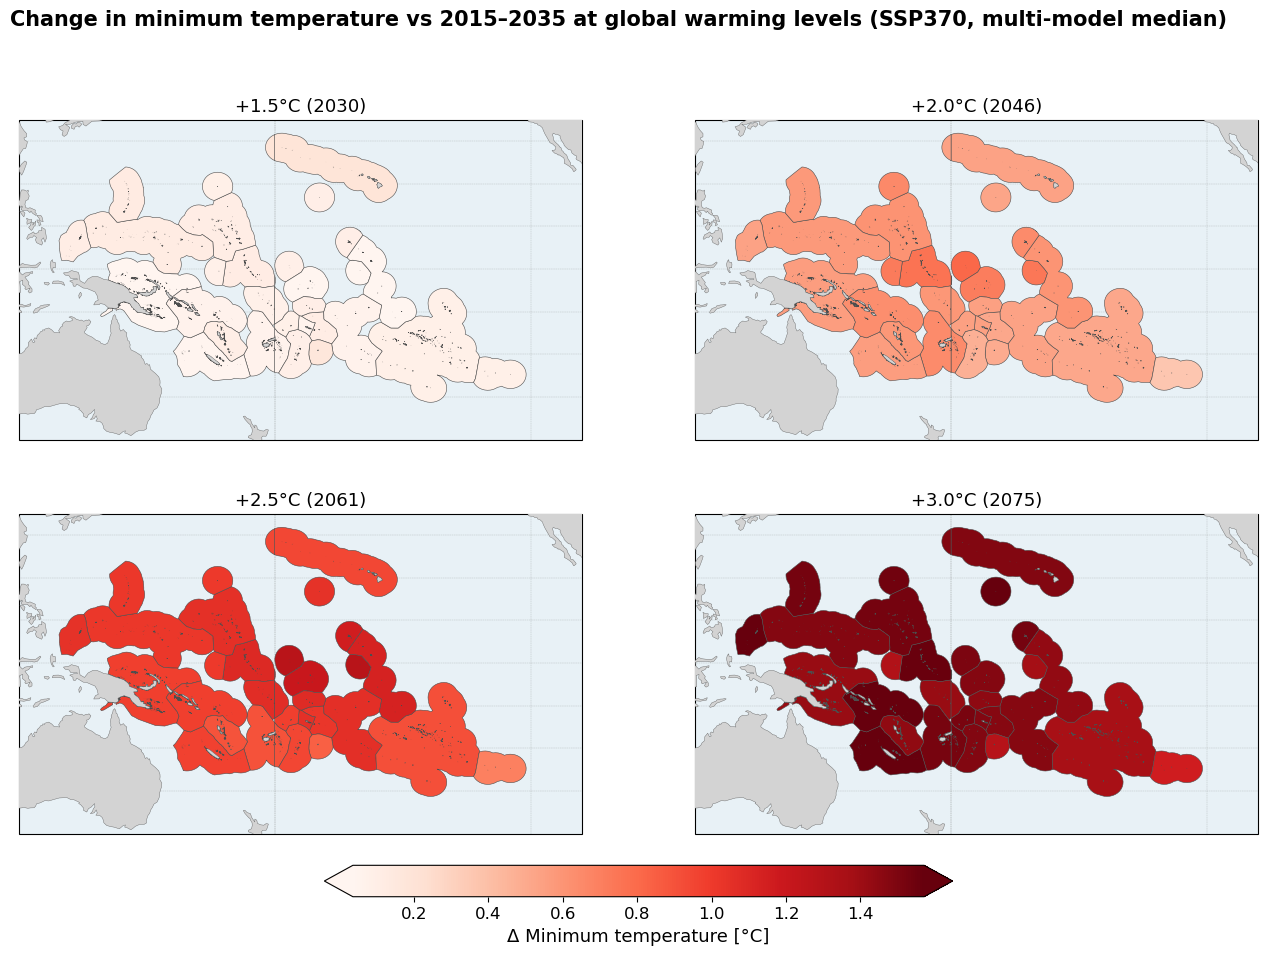

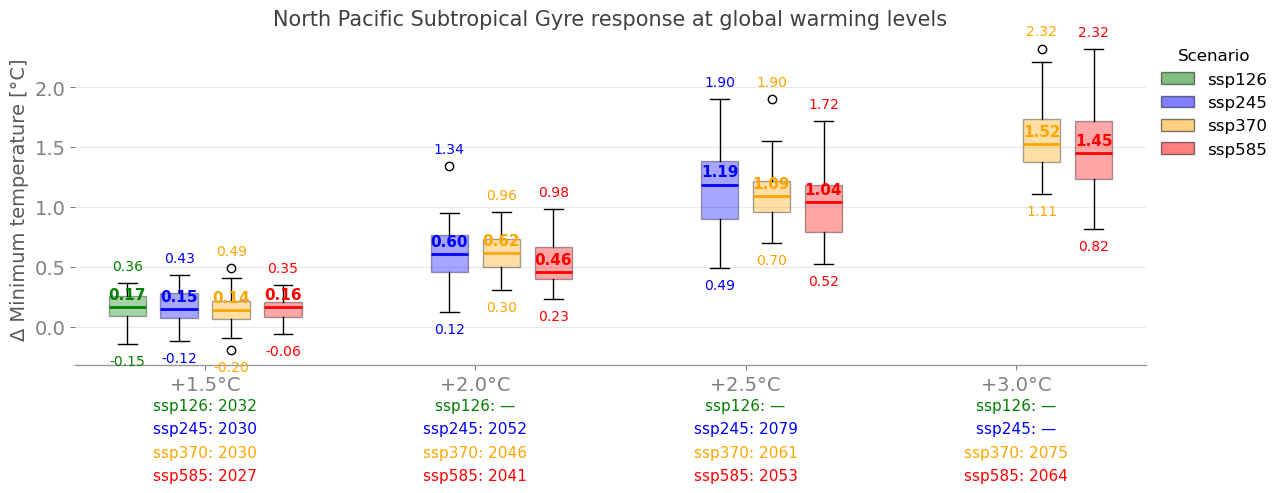

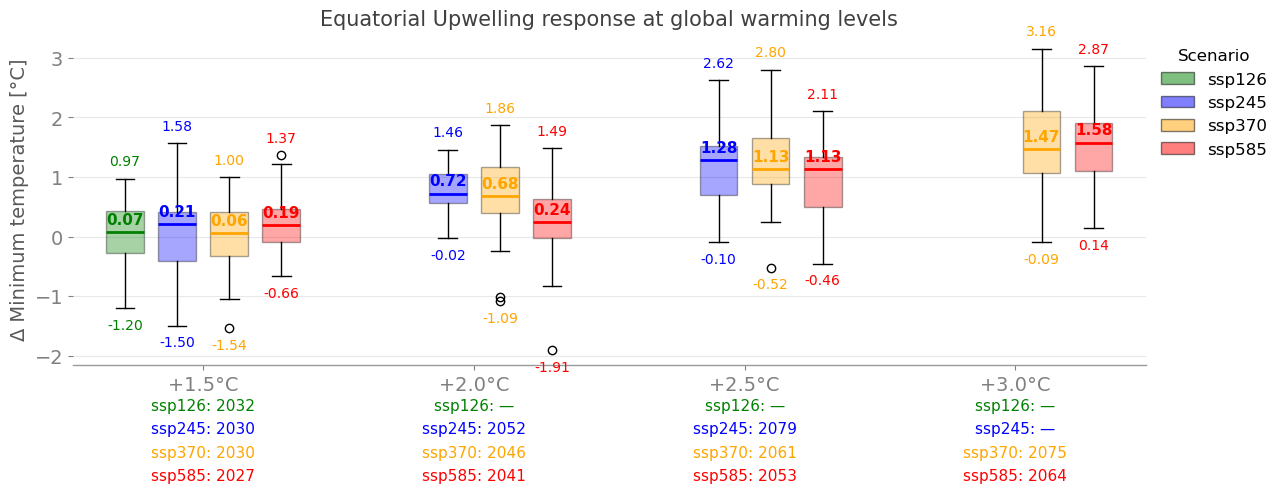

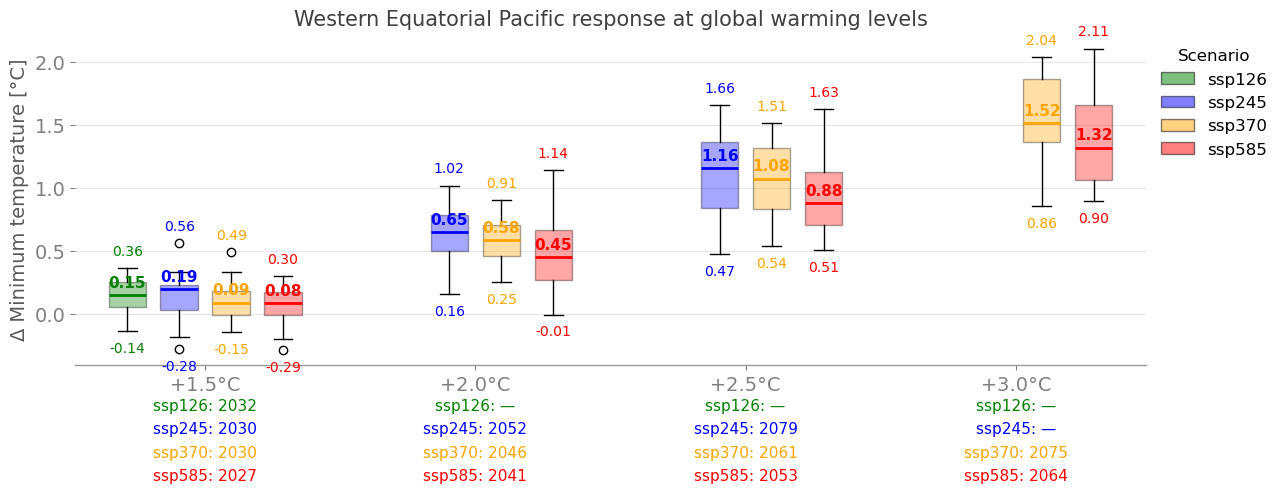

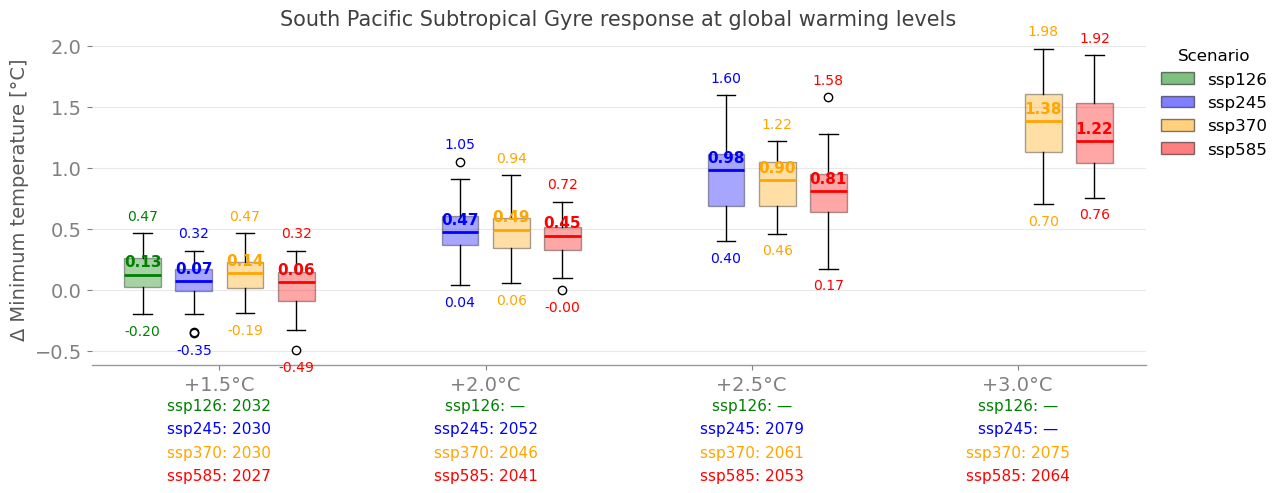

In [5]:
ds = reg.extract_regional_means("tasmin", eez, ssp_scenarios)
figs, tables = reg.indicator_report(ds, "tasmin", scenario_info, eez, ssp_scenarios, map_scenario, fig_dir, tables_dir)
tables["regions"]

## Maximum temperature

Annual maximum near-surface air temperature (°C).

,Region,Scenario,Warming level,Year,Models,Median,P10,P90,Min,Max
0,North Pacific Subtropical Gyre,SSP126,+1.5°C,2032,27,0.165,-0.054,0.314,-0.162,0.390
1,North Pacific Subtropical Gyre,SSP126,+2.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
2,North Pacific Subtropical Gyre,SSP126,+2.5°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
3,North Pacific Subtropical Gyre,SSP126,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
4,North Pacific Subtropical Gyre,SSP245,+1.5°C,2030,27,0.135,-0.056,0.329,-0.159,0.432
...,...,...,...,...,...,...,...,...,...,...
59,South Pacific Subtropical Gyre,SSP370,+3.0°C,2075,27,1.323,0.874,1.645,0.714,1.922
60,South Pacific Subtropical Gyre,SSP585,+1.5°C,2027,27,0.058,-0.169,0.240,-0.486,0.322
61,South Pacific Subtropical Gyre,SSP585,+2.0°C,2041,27,0.426,0.218,0.609,-0.030,0.724
62,South Pacific Subtropical Gyre,SSP585,+2.5°C,2053,27,0.765,0.469,0.976,0.164,1.536


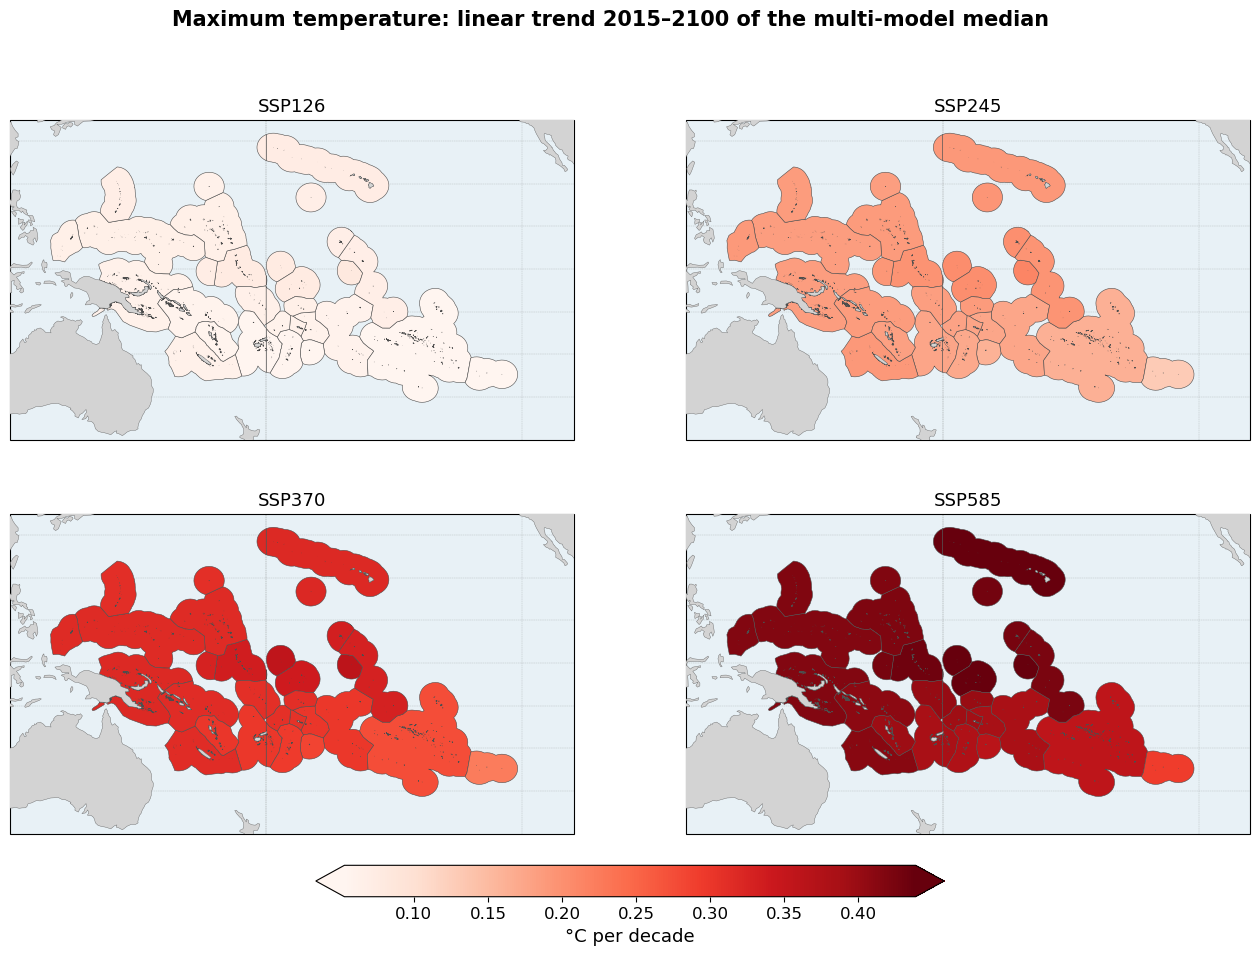

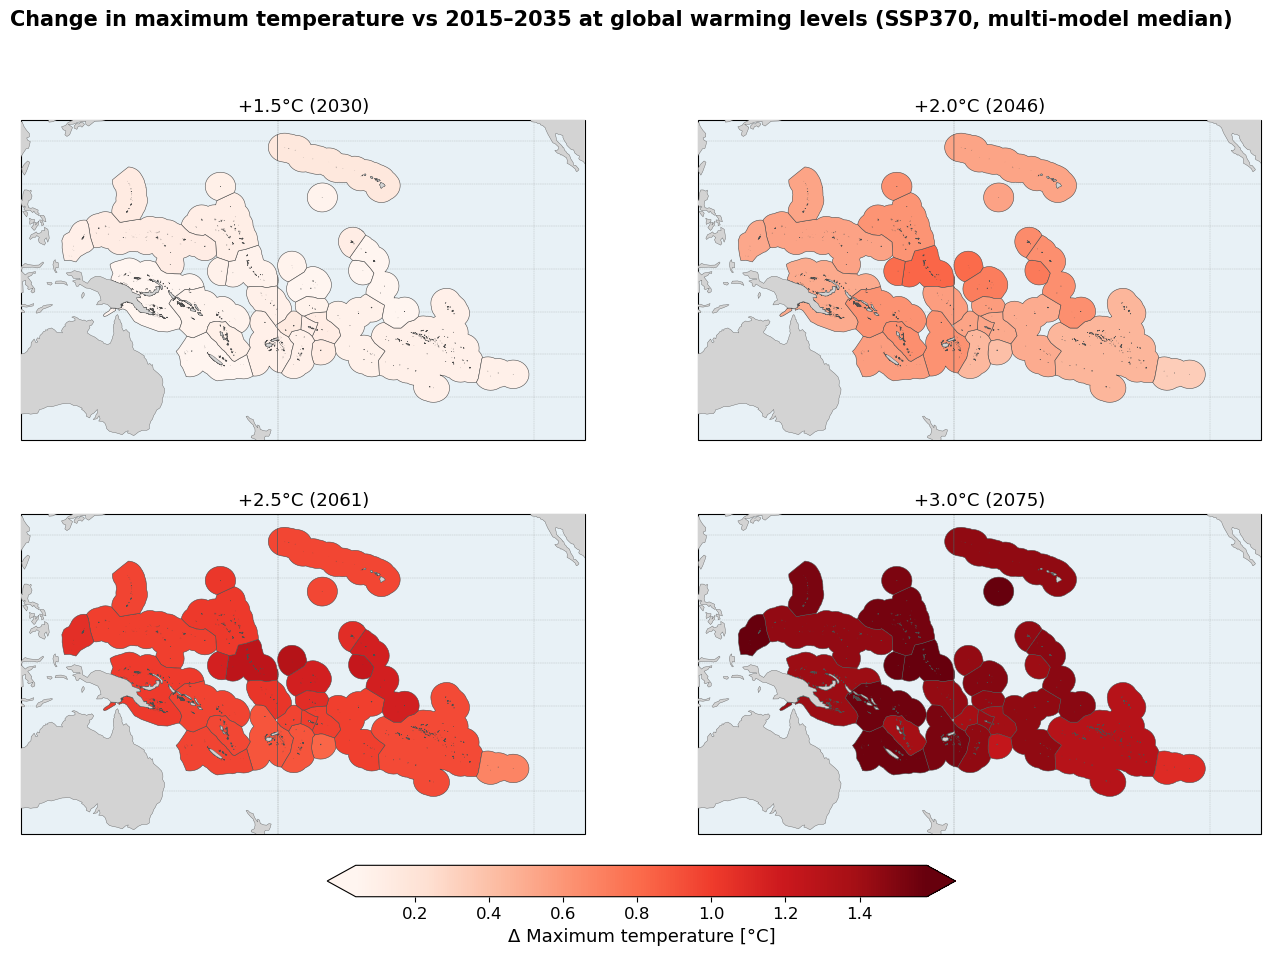

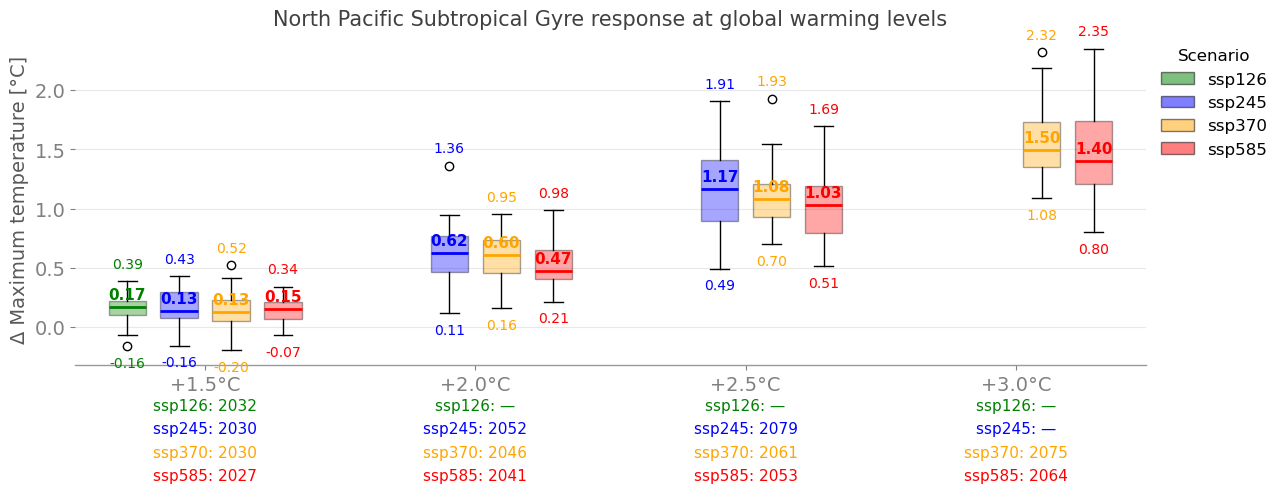

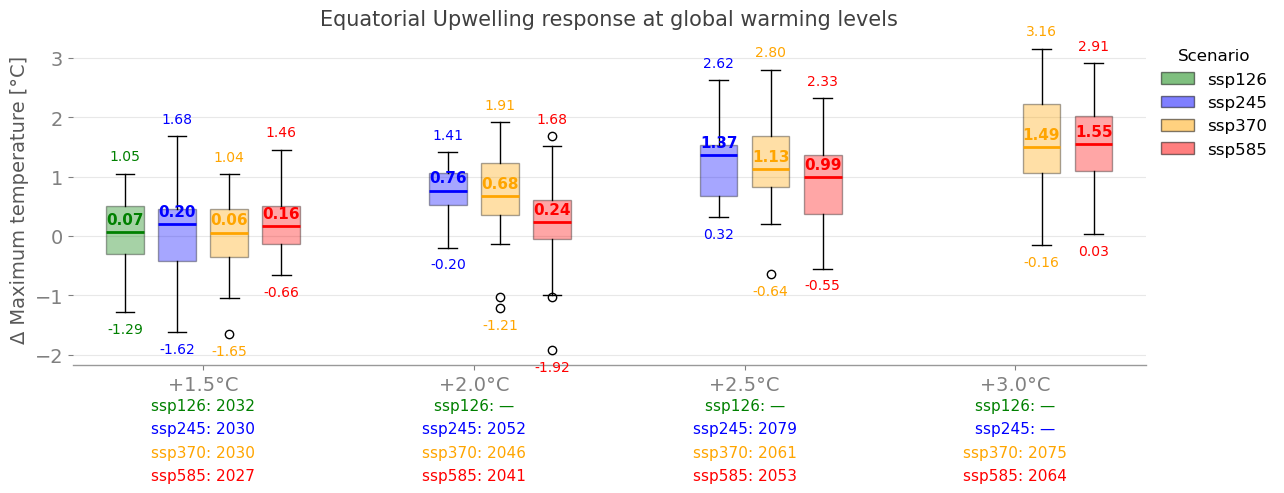

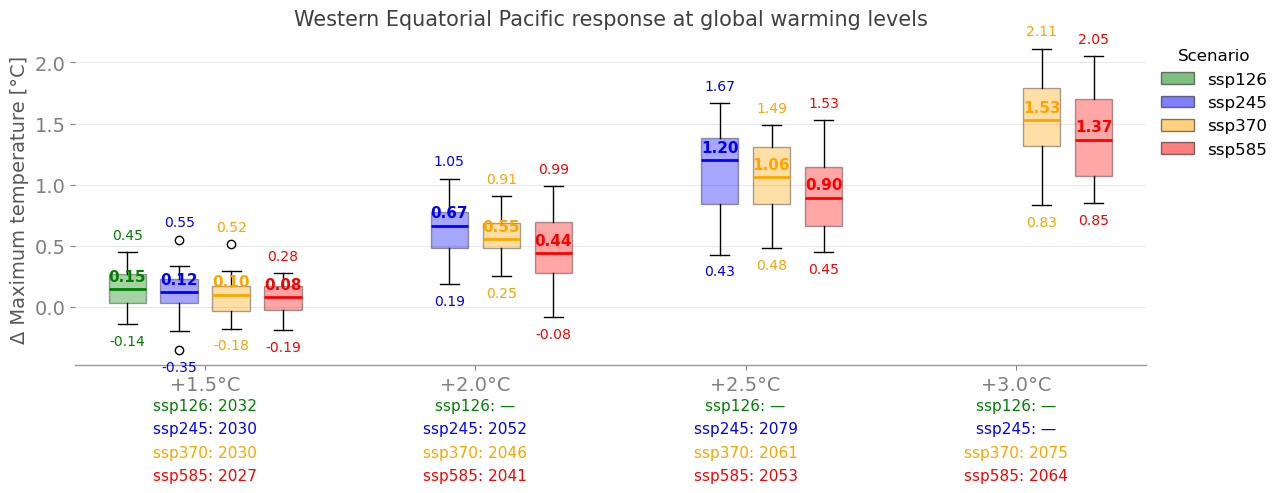

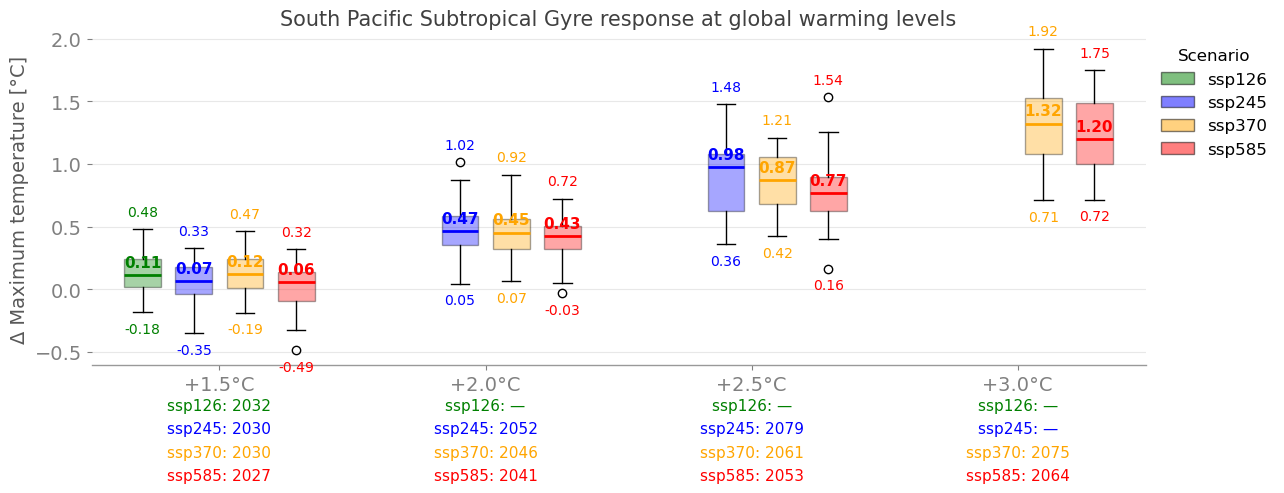

In [6]:
ds = reg.extract_regional_means("tasmax", eez, ssp_scenarios)
figs, tables = reg.indicator_report(ds, "tasmax", scenario_info, eez, ssp_scenarios, map_scenario, fig_dir, tables_dir)
tables["regions"]

## Warm days

Annual number of warm days.

,Region,Scenario,Warming level,Year,Models,Median,P10,P90,Min,Max
0,North Pacific Subtropical Gyre,SSP126,+1.5°C,2032,26,14.5,-12.6,26.4,-40.3,39.9
1,North Pacific Subtropical Gyre,SSP126,+2.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
2,North Pacific Subtropical Gyre,SSP126,+2.5°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
3,North Pacific Subtropical Gyre,SSP126,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
4,North Pacific Subtropical Gyre,SSP245,+1.5°C,2030,27,13.5,-4.5,26.7,-35.7,45.3
...,...,...,...,...,...,...,...,...,...,...
59,South Pacific Subtropical Gyre,SSP370,+3.0°C,2075,27,67.5,45.3,89.7,33.2,112.2
60,South Pacific Subtropical Gyre,SSP585,+1.5°C,2027,27,3.2,-12.3,15.4,-20.5,25.1
61,South Pacific Subtropical Gyre,SSP585,+2.0°C,2041,27,21.7,7.3,38.7,-5.7,43.7
62,South Pacific Subtropical Gyre,SSP585,+2.5°C,2053,27,40.2,27.9,58.5,18.3,80.5


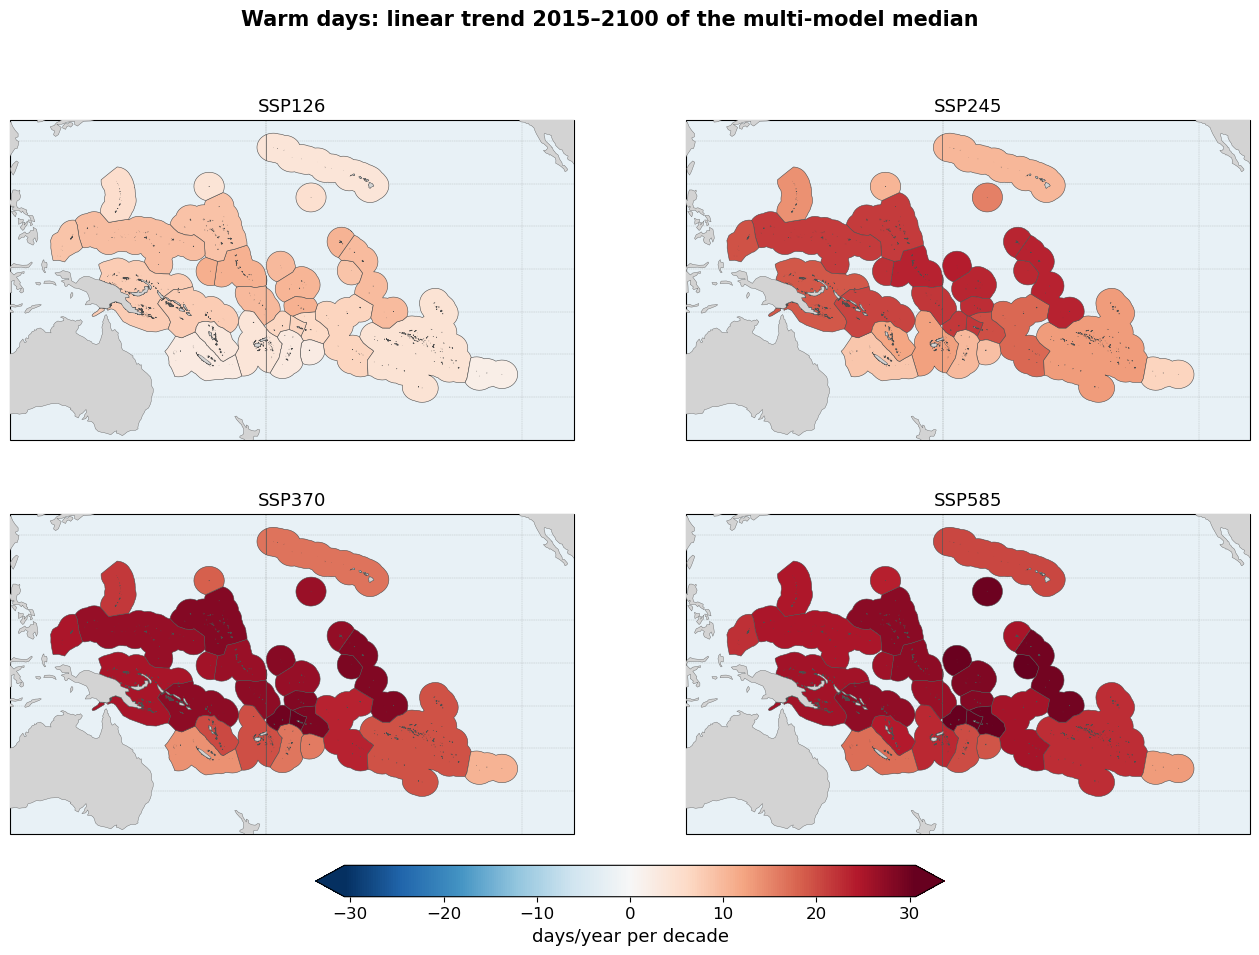

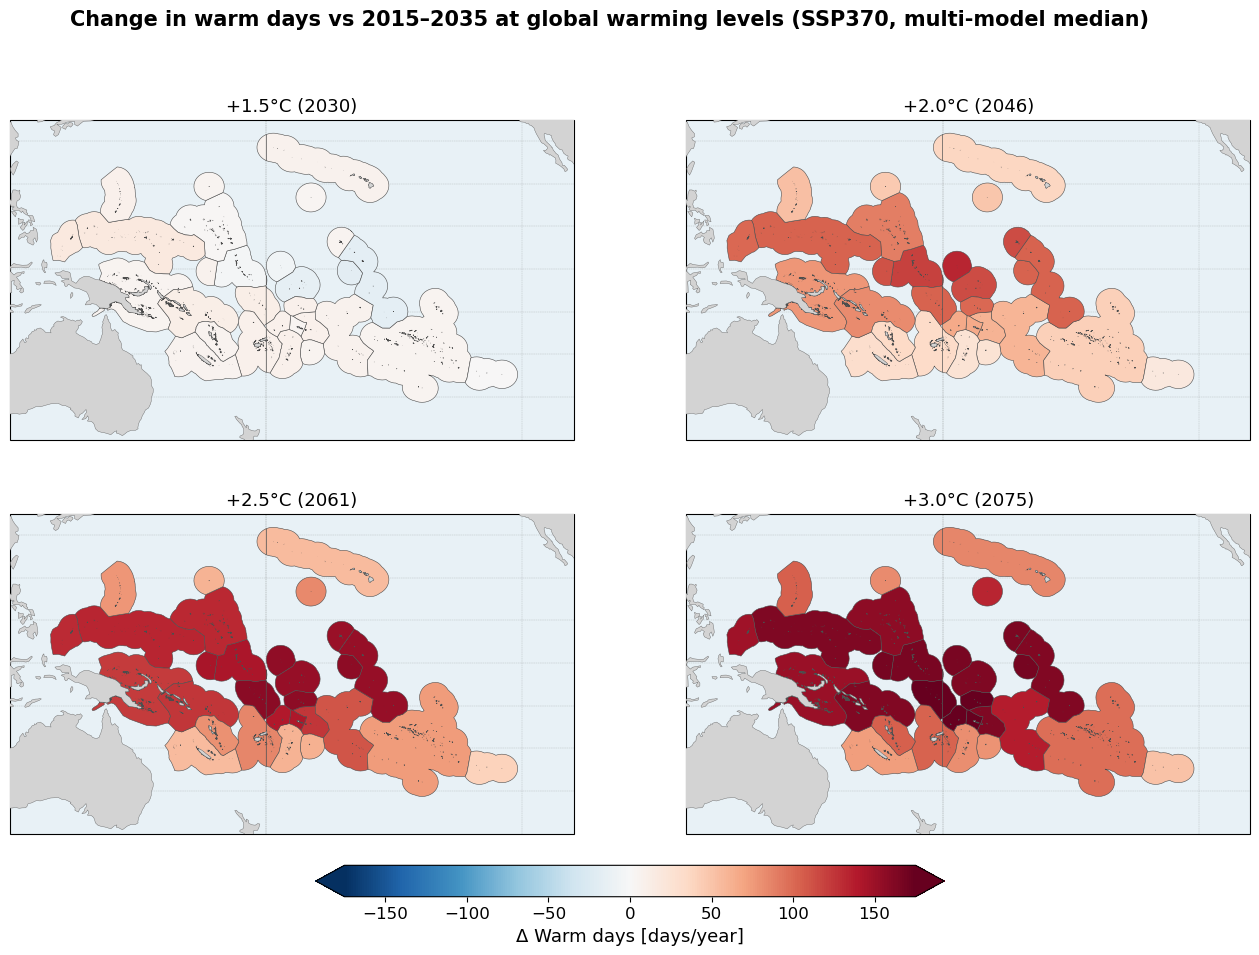

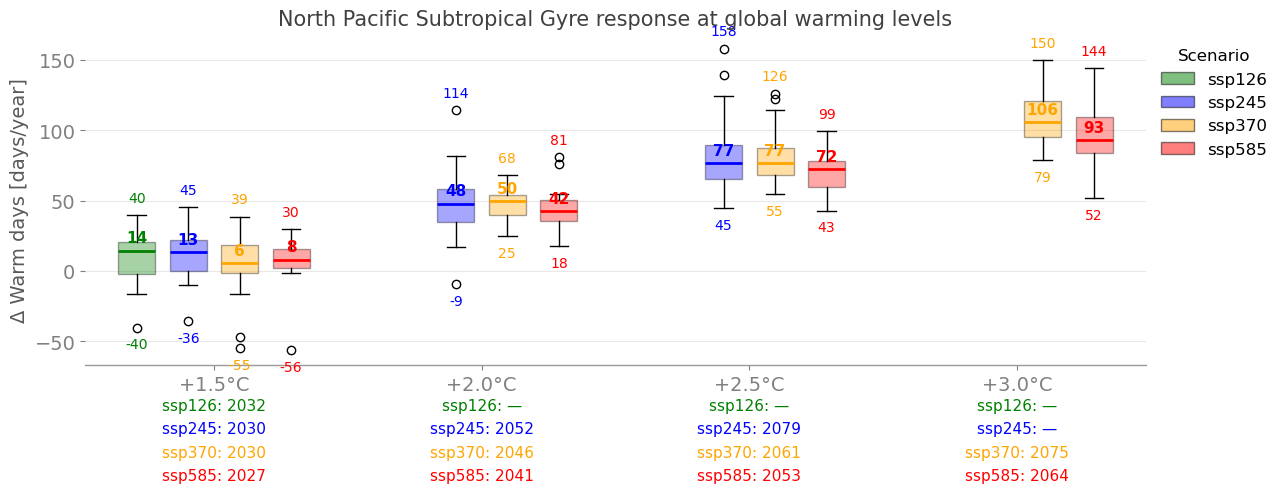

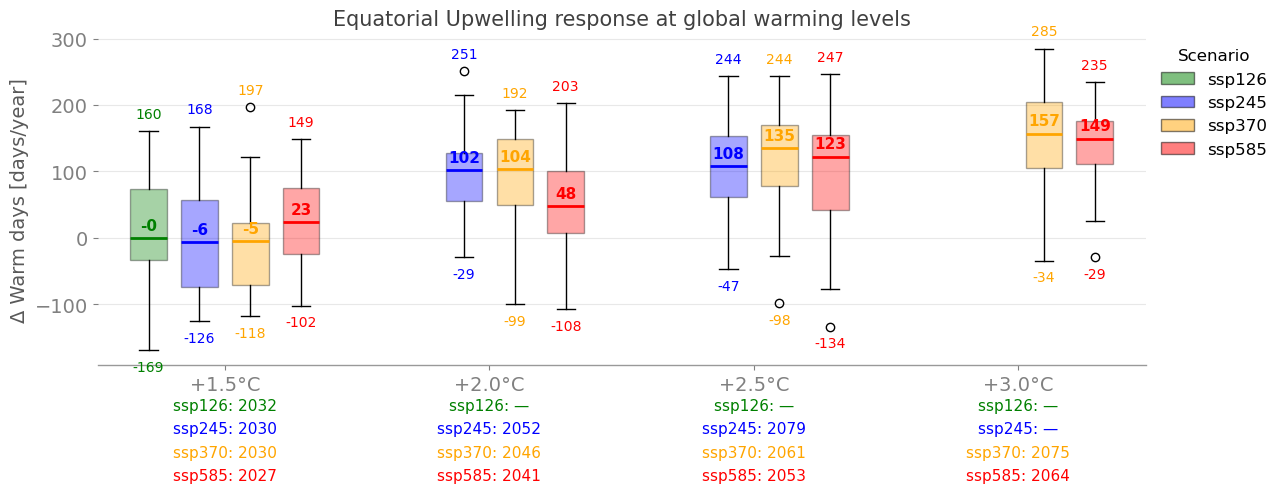

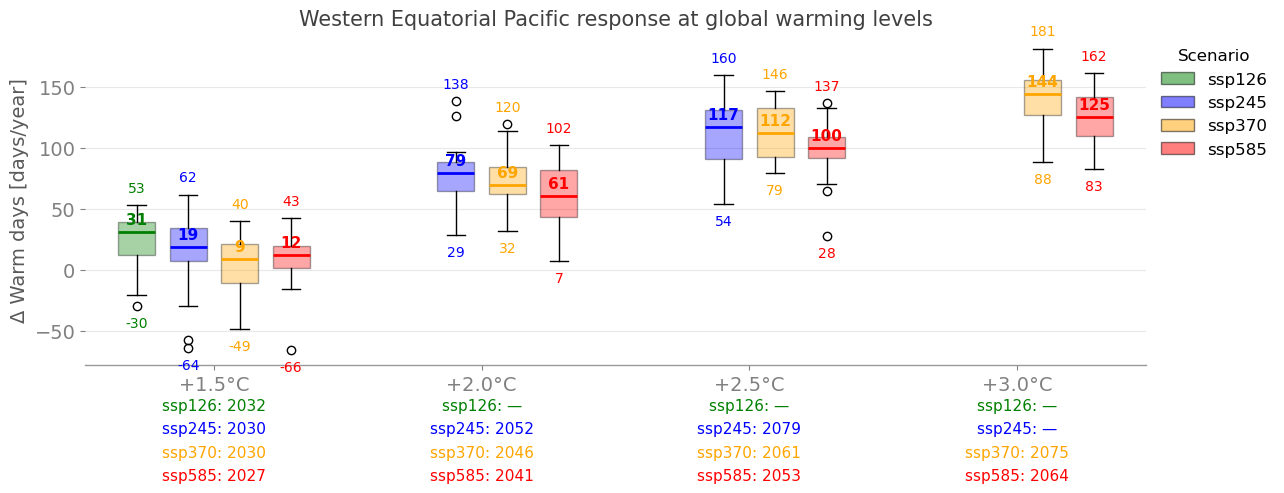

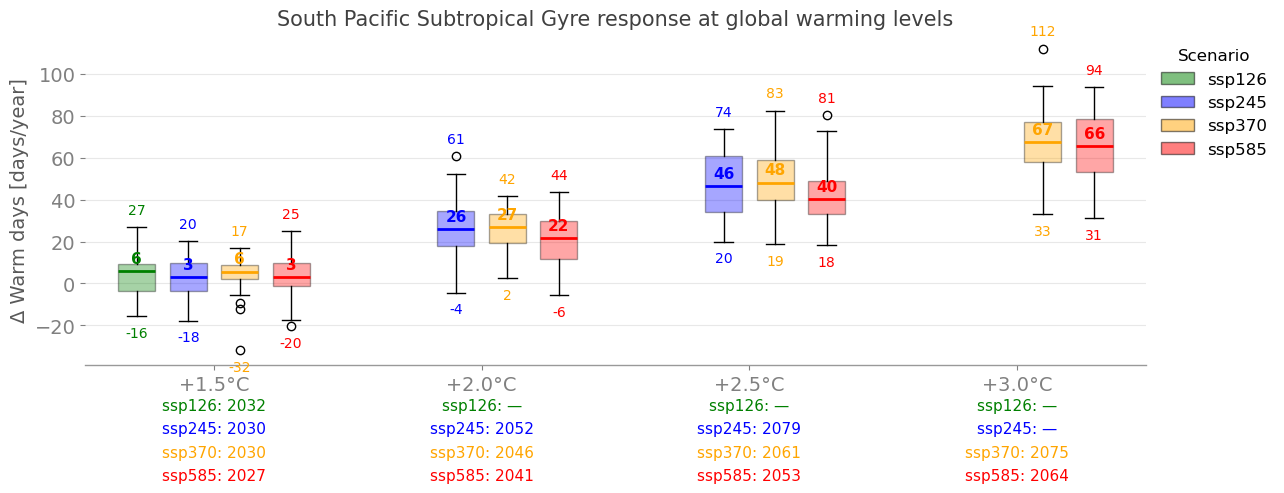

In [7]:
ds = reg.extract_regional_means("warmdays", eez, ssp_scenarios)
figs, tables = reg.indicator_report(ds, "warmdays", scenario_info, eez, ssp_scenarios, map_scenario, fig_dir, tables_dir)
tables["regions"]

## Cold nights

Annual number of cold nights.

,Region,Scenario,Warming level,Year,Models,Median,P10,P90,Min,Max
0,North Pacific Subtropical Gyre,SSP126,+1.5°C,2032,25,-1.9,-5.8,2.5,-7.2,3.9
1,North Pacific Subtropical Gyre,SSP126,+2.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
2,North Pacific Subtropical Gyre,SSP126,+2.5°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
3,North Pacific Subtropical Gyre,SSP126,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
4,North Pacific Subtropical Gyre,SSP245,+1.5°C,2030,26,-2.6,-5.7,-0.6,-9.4,2.9
...,...,...,...,...,...,...,...,...,...,...
59,South Pacific Subtropical Gyre,SSP370,+3.0°C,2075,25,-14.0,-18.2,-8.4,-20.7,2.7
60,South Pacific Subtropical Gyre,SSP585,+1.5°C,2027,26,-1.1,-5.9,5.3,-8.4,13.0
61,South Pacific Subtropical Gyre,SSP585,+2.0°C,2041,26,-8.4,-11.9,-3.4,-15.4,-0.9
62,South Pacific Subtropical Gyre,SSP585,+2.5°C,2053,26,-10.4,-14.7,-6.2,-18.0,-3.6


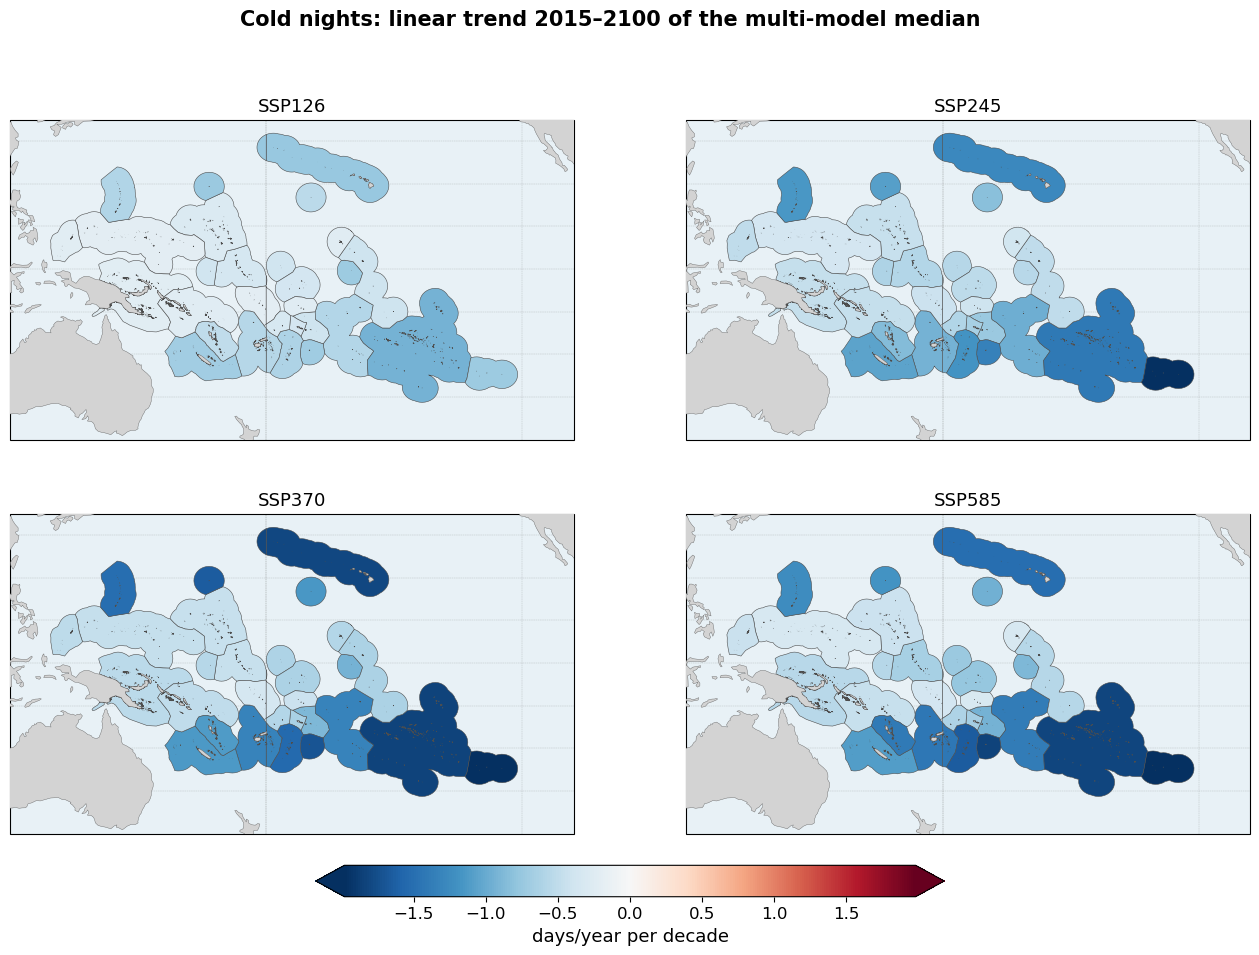

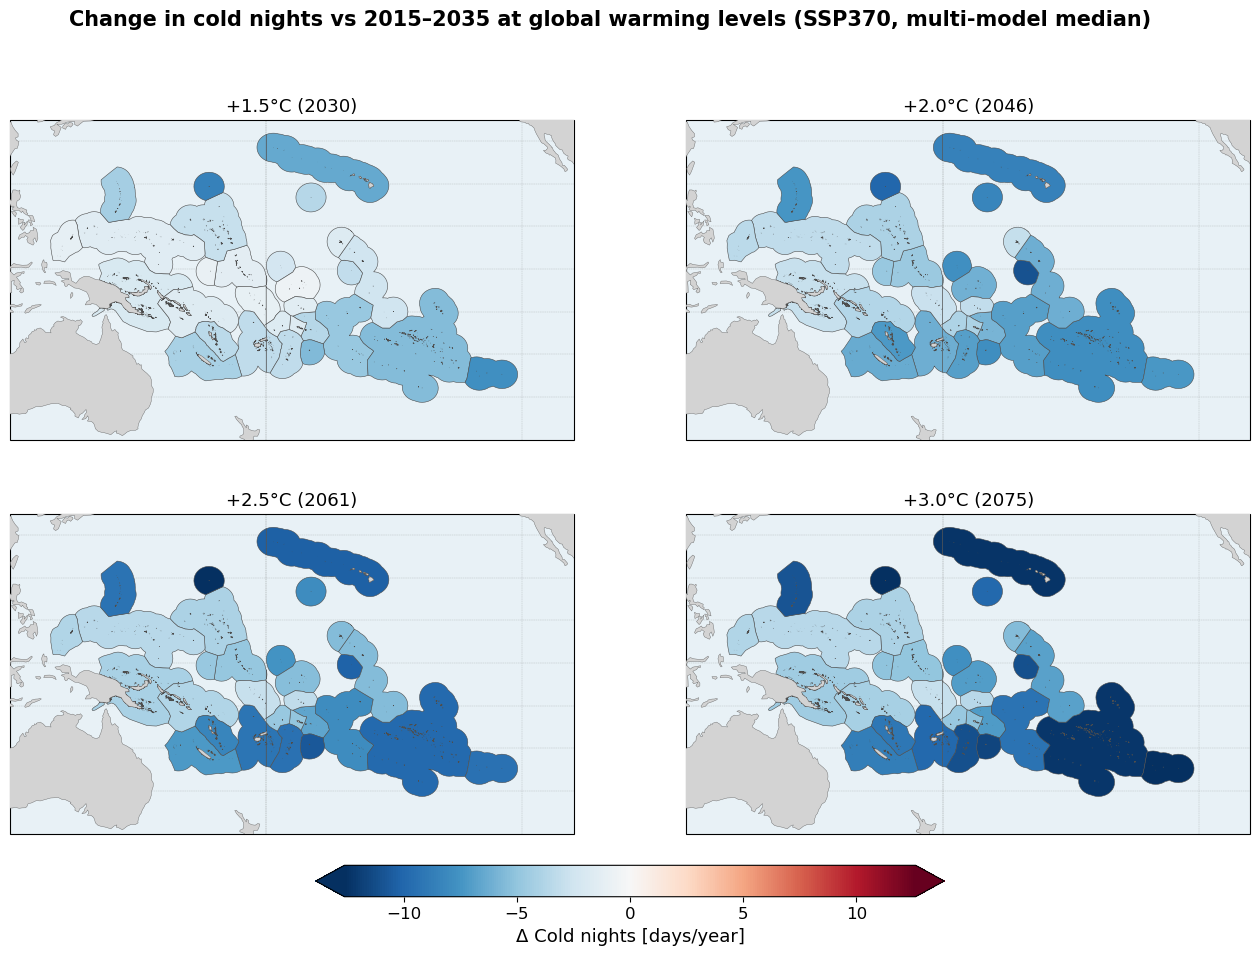

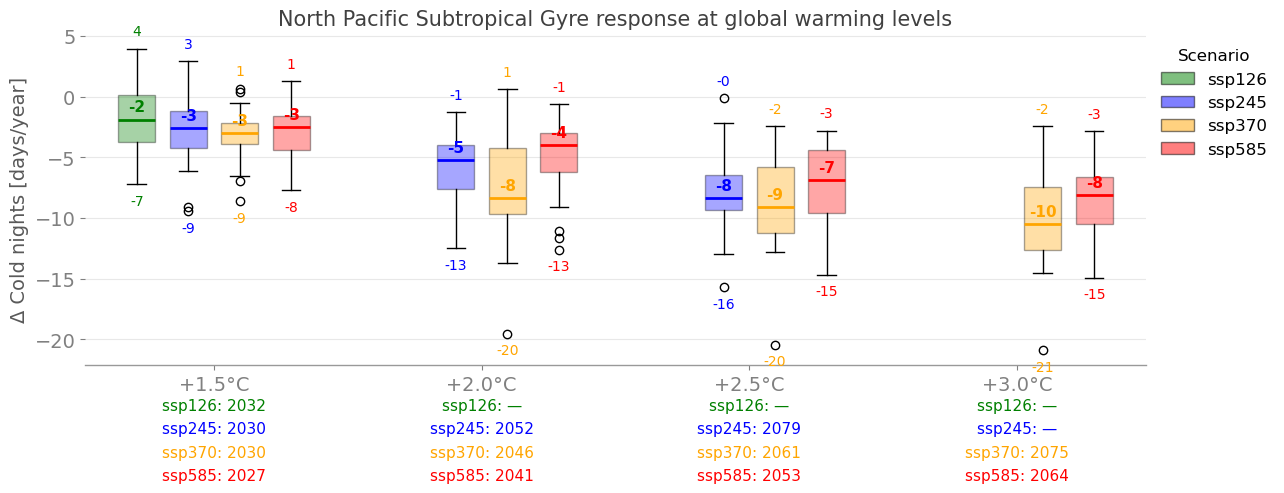

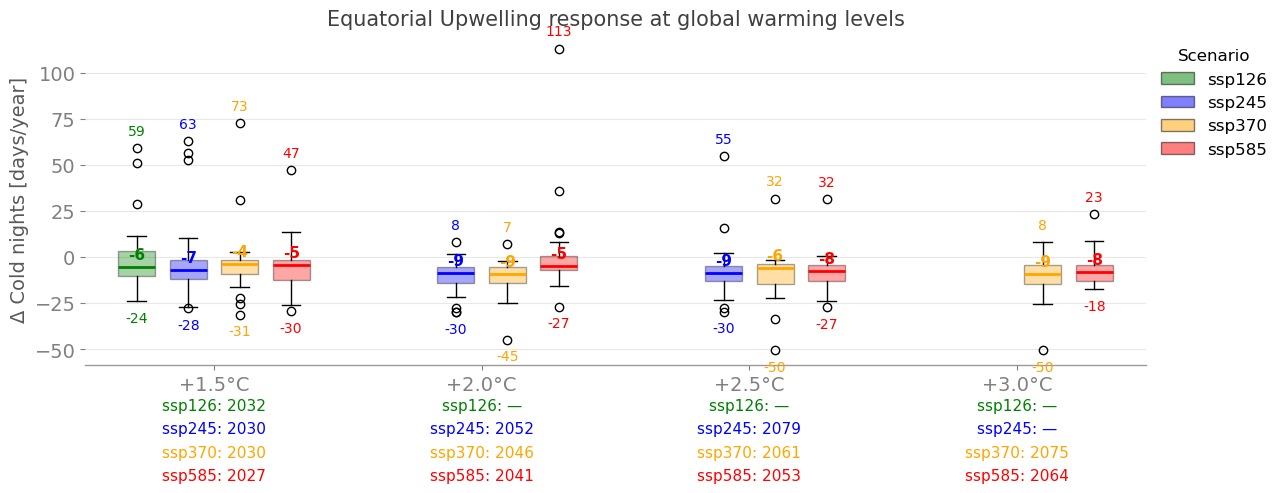

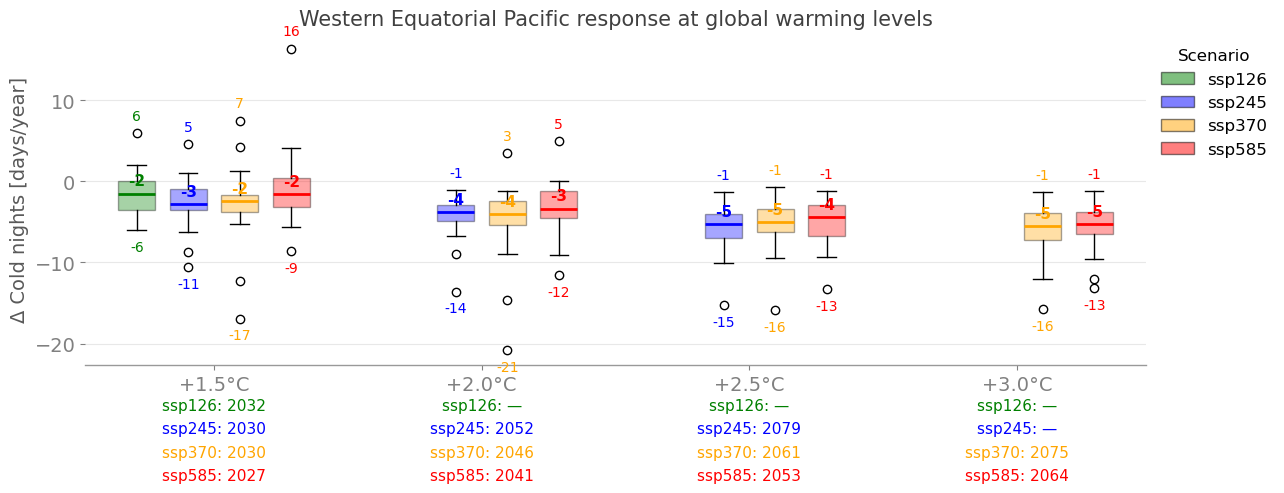

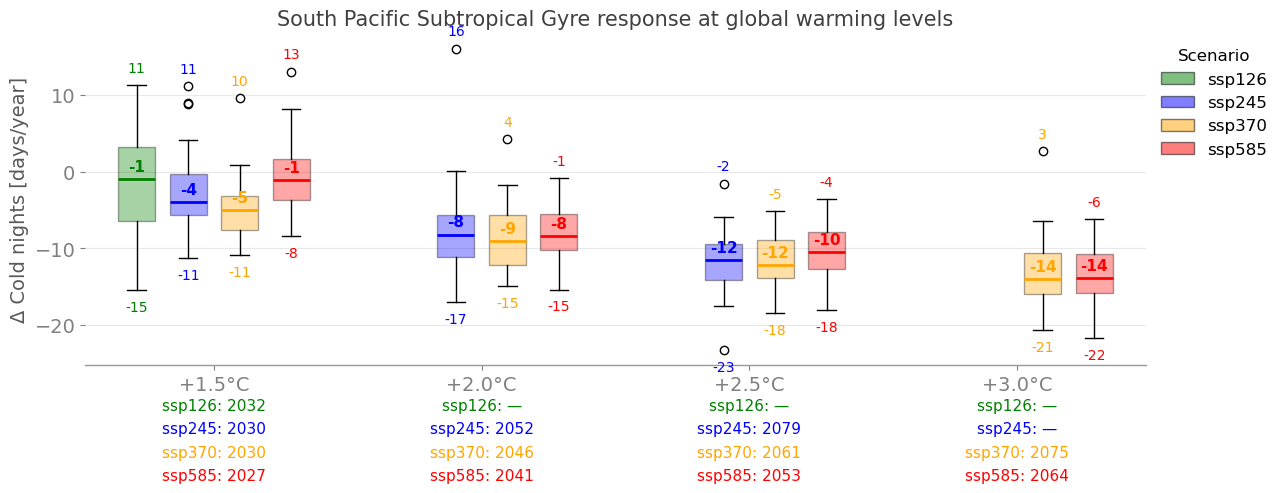

In [8]:
ds = reg.extract_regional_means("coldnights", eez, ssp_scenarios)
figs, tables = reg.indicator_report(ds, "coldnights", scenario_info, eez, ssp_scenarios, map_scenario, fig_dir, tables_dir)
tables["regions"]